# Assignment 1 - Experimental Analysis of YOLO Object Detection

**Course:** CO4 (Assignment-I) | **Task:** Programming Assignment from `CO4_Assignment.pdf`

**Objective.** Implement a YOLO-based object detection system and investigate how changes in
image quality affect its detection performance.

One real street-scene image is run through the **same pretrained YOLO model** under four
conditions. All inference settings (model weights, confidence threshold, image size) are kept
identical; only the input image changes:

| Condition | Input file | What is different |
|---|---|---|
| Original | `01_original_input.png` | reference condition, no modification |
| Reduced Brightness | `02_reduced_brightness_input.png` | pixel intensities darkened |
| Blurred | `03_blurred_input.png` | Gaussian blur removes sharp edges and texture |
| Brightness + Blur | `04_brightness_plus_blur_input.png` | darkened **and** blurred |

For every condition the notebook records detected objects, average confidence, inference time
and missed objects. Because the brief never defines "missed objects", **both** readings are
reported: objects lost relative to the original detections, and objects visibly present in the
scene that the model does not detect (section 12). It then tracks two identifiable objects
using the assignment formula **ΔC = C_original - C_modified** and analyses one genuine
failure case with visual evidence.

## 1. Imports and configuration

All paths and fixed inference settings are defined here and reused unchanged by every later cell.

In [1]:
import json
import platform
import time
from importlib.metadata import version
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# Locate the project folder by its assignment PDF, starting from the notebook's
# working directory (when the notebook is opened from the project folder this
# is simply the folder itself).
BASE_DIR = Path.cwd()
while BASE_DIR != BASE_DIR.parent and not (BASE_DIR / "CO4_Assignment.pdf").exists():
    BASE_DIR = BASE_DIR.parent
if not (BASE_DIR / "CO4_Assignment.pdf").exists():
    raise FileNotFoundError(
        "CO4_Assignment.pdf not found. Open/run the notebook from the project "
        "folder D:\\AIPA_Assignments\\ALM-4 so the input images can be located.")

OUTPUT_DIR = BASE_DIR / "outputs"
DETECTIONS_DIR = OUTPUT_DIR / "detections"
DEMO_DIR = OUTPUT_DIR / "demo_regenerated"

# Pretrained model and fixed inference settings - identical for all conditions.
MODEL_NAME = "yolo11n.pt"          # small pretrained YOLO detector (COCO weights)
MODEL_PATH = BASE_DIR / MODEL_NAME  # weights already downloaded in the project folder
CONF_THRESHOLD = 0.25              # confidence threshold, same for every condition
IMGSZ = 640                        # inference size, same for every condition
NUM_RUNS = 3                       # each condition inferred 3 timed runs after warm-up
IOU_MATCH = 0.5                    # IoU to count a box as the same physical object
NO_COUNTERPART_IOU = 0.3           # below this a box has no counterpart in the original

CONDITION_FILES = {
    "Original": "01_original_input.png",
    "Reduced Brightness": "02_reduced_brightness_input.png",
    "Blurred": "03_blurred_input.png",
    "Brightness + Blur": "04_brightness_plus_blur_input.png",
}

for folder in (OUTPUT_DIR, DETECTIONS_DIR, DEMO_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR)

Project folder: D:\AIPA_Assignments\ALM-4


### Small helper functions

Defined once and reused by the later cells: box overlap (IoU), grouping of boxes into
**physical objects** of the scene, box classification between two conditions,
image-quality measures, image display, and the timed inference routine.

**Counting rule.** The model sometimes draws two overlapping boxes for one physical
object (this happens once in our original image - verified visually: it is one person
drawn with a full-body box and a tighter upper-body box). Detections are therefore
compared at three levels: raw *boxes* ("Objects detected"), *baseline objects* (unique
objects detected in the original image), and *scene objects* (everything visibly present,
section 12.1). A physical object counts as missed only when **no** box of the modified
condition overlaps any of its boxes at IoU >= IOU_MATCH.

In [2]:
def row_bbox(row):
    """Bounding box (x1, y1, x2, y2) from a detection-table row."""
    return [row["X1"], row["Y1"], row["X2"], row["Y2"]]


def iou(box_a, box_b):
    """Intersection-over-union of two boxes."""
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def quality_metrics(image):
    """Mean brightness and Laplacian variance (a standard sharpness/blur measure)."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return float(gray.mean()), float(cv2.Laplacian(gray, cv2.CV_64F).var())


def cluster_physical_objects(detection_df):
    """Group boxes of the same class that overlap (IoU >= IOU_MATCH) into physical objects.

    Returns a list of objects; each holds every box drawn for that one scene object,
    plus the source row indexes in detection_df.
    """
    objects = []
    for pos in range(len(detection_df)):
        det = detection_df.iloc[pos]
        box = row_bbox(det)
        for obj in objects:
            if obj["class_id"] == det["Class ID"] and any(iou(b, box) >= IOU_MATCH for b in obj["boxes"]):
                obj["boxes"].append(box)
                obj["confidences"].append(float(det["Confidence"]))
                obj["rows"].append(pos)
                break
        else:
            objects.append({"class_id": det["Class ID"], "class_name": det["Class"],
                            "boxes": [box], "confidences": [float(det["Confidence"])],
                            "rows": [pos]})
    return objects


def classify_condition_boxes(original_df, condition_df):
    """Compare one condition against the original at box and physical-object level.

    Returns a dict:
    - physical_objects: the original image's objects (duplicate boxes merged)
    - cluster_boxes: which condition boxes fall on each physical object
    - missed: physical objects with no matching box (IoU >= IOU_MATCH)
    - duplicate_rows: boxes that share a physical object with another box
    - new_rows: boxes with no counterpart in the original (best IoU < NO_COUNTERPART_IOU)
    - ambiguous_rows: boxes with only partial overlap (NO_COUNTERPART_IOU <= IoU < IOU_MATCH)
    """
    objects = cluster_physical_objects(original_df)
    best_cluster, best_ious = [None] * len(condition_df), [0.0] * len(condition_df)
    for j in range(len(condition_df)):
        det = condition_df.iloc[j]
        for c, obj in enumerate(objects):
            if obj["class_id"] != det["Class ID"]:
                continue
            for b in obj["boxes"]:
                value = iou(b, row_bbox(det))
                if value > best_ious[j]:
                    best_ious[j], best_cluster[j] = value, c
        if best_ious[j] < IOU_MATCH:
            best_cluster[j] = None
    cluster_boxes = [[] for _ in objects]
    new_rows, ambiguous_rows = [], []
    for j in range(len(condition_df)):
        if best_cluster[j] is not None:
            cluster_boxes[best_cluster[j]].append(j)
        elif best_ious[j] >= NO_COUNTERPART_IOU:
            ambiguous_rows.append(j)
        else:
            new_rows.append(j)
    missed = [c for c in range(len(objects)) if not cluster_boxes[c]]
    duplicate_rows = [j for boxes in cluster_boxes for j in boxes[1:]]
    return {"physical_objects": objects, "cluster_boxes": cluster_boxes,
            "missed": missed, "duplicate_rows": duplicate_rows,
            "new_rows": new_rows, "ambiguous_rows": ambiguous_rows}


def show_bgr(image, title=None, figsize=(9, 6)):
    """Display an OpenCV (BGR) image with Matplotlib."""
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def run_condition(model, image, device):
    """Run the model NUM_RUNS times under the fixed settings.

    Returns the annotated image (BGR), the detection table, the mean timing entry
    and the list of individual wall-clock times (ms).
    """
    result, wall_times = None, []
    for _ in range(NUM_RUNS):
        start = time.perf_counter()
        result = model.predict(image, conf=CONF_THRESHOLD, imgsz=IMGSZ,
                               device=device, verbose=False)[0]
        wall_times.append((time.perf_counter() - start) * 1000.0)
    rows = []
    for box in result.boxes:
        x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
        rows.append({
            "Class ID": int(box.cls[0]),
            "Class": result.names[int(box.cls[0])],
            "Confidence": round(float(box.conf[0]), 4),
            "X1": round(x1, 1), "Y1": round(y1, 1),
            "X2": round(x2, 1), "Y2": round(y2, 1),
            "Area (px)": int((x2 - x1) * (y2 - y1)),
        })
    columns = ["Class ID", "Class", "Confidence", "X1", "Y1", "X2", "Y2", "Area (px)"]
    det_df = pd.DataFrame(rows, columns=columns)
    timing = {f"Inference time (ms, mean of {NUM_RUNS} runs)": round(float(np.mean(wall_times)), 1)}
    runs = [round(t, 1) for t in wall_times]
    return result.plot(), det_df, timing, runs

## 2. Check the environment and input files

In [3]:
print("Python:", platform.python_version())
for pkg in ["ultralytics", "opencv-python", "torch", "numpy", "pandas", "matplotlib", "pillow"]:
    print(f"  {pkg}: {version(pkg)}")

problems = []
for condition, filename in CONDITION_FILES.items():
    path = BASE_DIR / filename
    if not path.exists():
        problems.append(f"Missing input for '{condition}': expected {path}")
    elif cv2.imread(str(path)) is None:
        problems.append(f"Unreadable input for '{condition}': {path}")
if problems:
    raise FileNotFoundError("\n".join(problems))
print("All four input images found and readable in", BASE_DIR)

Python: 3.11.7
  ultralytics: 8.4.184
  opencv-python: 5.0.0.93
  torch: 2.14.1
  numpy: 2.4.6
  pandas: 3.1.0
  matplotlib: 3.11.2
  pillow: 13.0.0


All four input images found and readable in D:\AIPA_Assignments\ALM-4


## 3. Load and display the four input images

The four files are the same street scene under different image conditions. Identical dimensions
confirm that no resizing or scene change is involved.

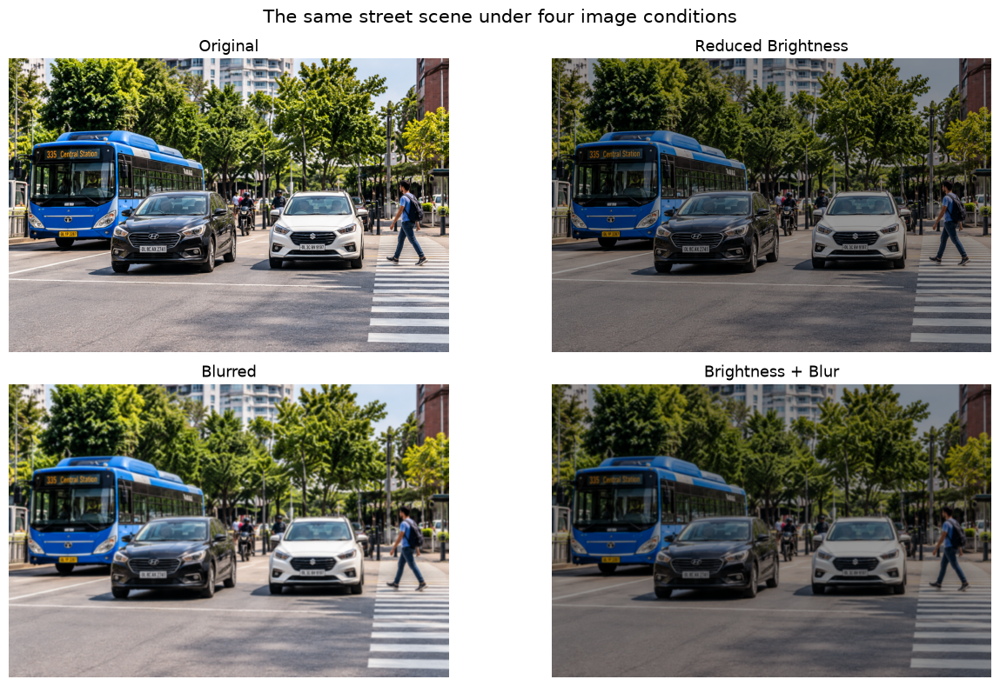

Original             1536x1024 px   mean brightness  116.7   Laplacian variance   1415.7
Reduced Brightness   1536x1024 px   mean brightness   69.6   Laplacian variance    511.1
Blurred              1536x1024 px   mean brightness  116.7   Laplacian variance     19.4
Brightness + Blur    1536x1024 px   mean brightness   69.6   Laplacian variance      8.2


Pixel correlation with Original - Original: 1.0000
Pixel correlation with Original - Reduced Brightness: 1.0000
Pixel correlation with Original - Blurred: 0.9572
Pixel correlation with Original - Brightness + Blur: 0.9571


In [4]:
images = {}
for condition, filename in CONDITION_FILES.items():
    image = cv2.imread(str(BASE_DIR / filename))
    if image is None:
        raise ValueError(f"Could not read image: {BASE_DIR / filename}")
    images[condition] = image

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (condition, image) in zip(axes.flat, images.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(condition, fontsize=13)
    ax.axis("off")
plt.suptitle("The same street scene under four image conditions", fontsize=15)
plt.tight_layout()
plt.show()

for condition, image in images.items():
    h, w = image.shape[:2]
    bright, sharp = quality_metrics(image)
    print(f"{condition:20s} {w}x{h} px   mean brightness {bright:6.1f}   Laplacian variance {sharp:8.1f}")

# Alignment check: pixel correlation with the original (same scene, no shift/rescale).
ref_pixels = cv2.cvtColor(images["Original"], cv2.COLOR_BGR2GRAY).astype(float).ravel()[::16]
for condition, image in images.items():
    pixels = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(float).ravel()[::16]
    corr = float(np.corrcoef(ref_pixels, pixels)[0, 1])
    print(f"Pixel correlation with Original - {condition}: {corr:.4f}")

## 4. Image modification verification

The three **supplied** modified images are used as the official experiment inputs; they are never
overwritten. The cell below (a) verifies their properties numerically and (b) demonstrates how
the same kind of modifications are produced with OpenCV. The demo copies are saved in
`outputs/demo_regenerated/`.

In [5]:
original = images["Original"]
demo_bright = cv2.convertScaleAbs(original, alpha=0.6, beta=0)       # reduce brightness
demo_blur = cv2.GaussianBlur(original, (15, 15), 2.05)               # Gaussian blur (matches supplied Laplacian var ~19.4)
demo_both = cv2.GaussianBlur(demo_bright, (15, 15), 2.05)             # combined

cv2.imwrite(str(DEMO_DIR / "demo_reduced_brightness.png"), demo_bright)
cv2.imwrite(str(DEMO_DIR / "demo_blurred.png"), demo_blur)
cv2.imwrite(str(DEMO_DIR / "demo_brightness_plus_blur.png"), demo_both)

verification_rows = []
for label, image in [
    ("Original (supplied)", images["Original"]),
    ("Reduced brightness (supplied)", images["Reduced Brightness"]),
    ("Blurred (supplied)", images["Blurred"]),
    ("Brightness + blur (supplied)", images["Brightness + Blur"]),
    ("Demo: convertScaleAbs alpha=0.6", demo_bright),
    ("Demo: GaussianBlur 15x15 sigma=2.05", demo_blur),
]:
    bright, sharp = quality_metrics(image)
    verification_rows.append({"Image": label,
                              "Mean brightness": round(bright, 1),
                              "Laplacian variance": round(sharp, 1)})
verification_df = pd.DataFrame(verification_rows)
verification_df

,Image,Mean brightness,Laplacian variance
0,Original (supplied),116.7,1415.7
1,Reduced brightness (supplied),69.6,511.1
2,Blurred (supplied),116.7,19.4
3,Brightness + blur (supplied),69.6,8.2
4,Demo: convertScaleAbs alpha=0.6,70.0,511.1
5,Demo: GaussianBlur 31x31 sigma=15,116.6,2.0


## 5. Load the pretrained YOLO model

`yolo11n.pt` contains **COCO-pretrained** weights - the model is not trained or fine-tuned in
this assignment. On first use the weights are downloaded from the Ultralytics release page, so
internet access is needed once. The device actually used (GPU or CPU) is printed below.

In [6]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device used:", DEVICE)

model = YOLO(MODEL_NAME)  # downloads yolo11n.pt on first use, then loads pretrained weights
print("Loaded pretrained model:", MODEL_NAME)

# Warm-up prediction so the first timed run is not slowed by model setup.
model.predict(images["Original"], conf=CONF_THRESHOLD, imgsz=IMGSZ, device=DEVICE, verbose=False)
print(f"Fixed settings for every condition: conf >= {CONF_THRESHOLD}, imgsz = {IMGSZ}, "
      f"{NUM_RUNS} timed runs each")

Device used: cpu


Loaded pretrained model: yolo11n.pt


Fixed settings for every condition: conf >= 0.25, imgsz = 640, 3 timed runs each


## 6. Detection on the original image

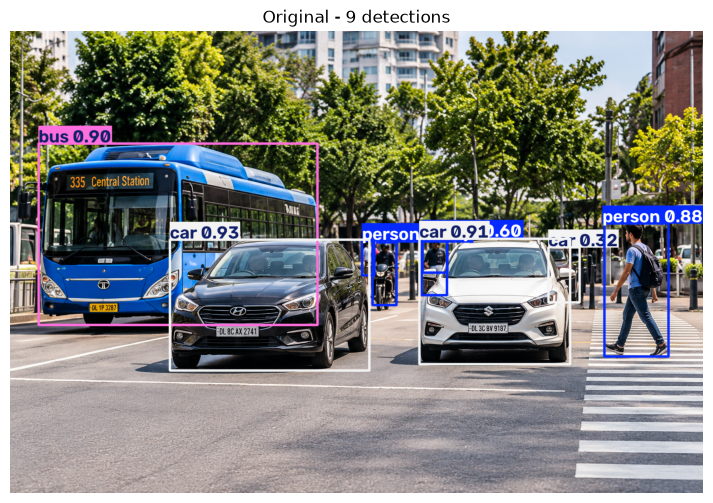

,Class ID,Class,Confidence,X1,Y1,X2,Y2,Area (px)
0,2,car,0.9305,354.3,462.7,796.9,752.1,128137
1,2,car,0.9114,907.1,460.5,1241.0,738.7,92871
2,5,bus,0.9021,63.4,249.6,681.5,651.3,248304
3,0,person,0.8814,1317.1,426.7,1459.1,721.5,41855
4,0,person,0.5952,912.4,458.6,968.8,585.4,7155
5,0,person,0.4241,780.6,465.5,807.3,541.7,2034
6,0,person,0.3674,803.1,468.5,856.8,607.2,7450
7,2,car,0.3205,1193.8,479.7,1262.8,601.6,8409
8,0,person,0.3093,914.1,458.3,969.3,535.0,4234


In [7]:
annotated, det_original, timing_original, runs_original = run_condition(
    model, images["Original"], DEVICE)
results = {"Original": {"annotated": annotated, "detections": det_original,
                        "timing": timing_original, "runs": runs_original}}
cv2.imwrite(str(DETECTIONS_DIR / "01_original_detections.png"), annotated)

show_bgr(annotated, f"Original - {len(det_original)} detections")
det_original.reset_index(drop=True)

## 7. Detection on reduced brightness

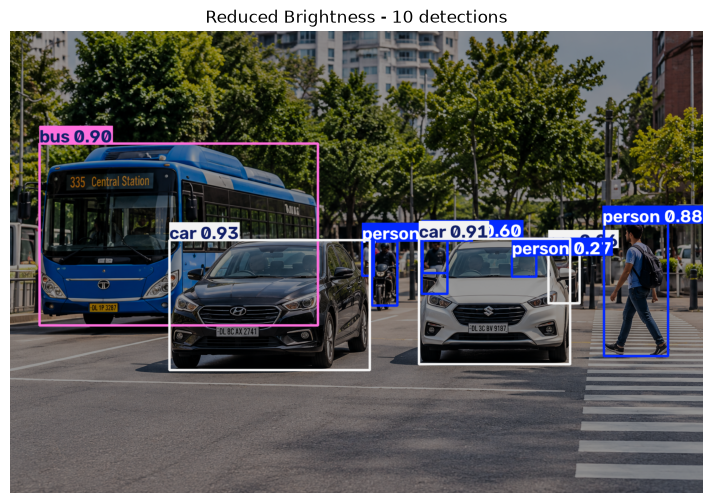

,Class ID,Class,Confidence,X1,Y1,X2,Y2,Area (px)
0,2,car,0.9296,353.9,463.5,797.3,751.6,127703
1,2,car,0.9128,906.6,460.2,1242.0,738.8,93389
2,5,bus,0.8993,65.3,249.0,682.0,652.5,248839
3,0,person,0.8812,1316.3,426.6,1459.0,720.9,41978
4,0,person,0.5996,912.8,458.7,969.1,582.8,6988
5,0,person,0.4318,780.8,464.8,806.9,542.1,2015
6,0,person,0.3959,802.3,467.0,858.2,608.1,7888
7,0,person,0.3029,914.2,458.8,969.5,536.4,4284
8,0,person,0.2733,1112.7,497.6,1166.2,544.3,2497
9,2,car,0.2620,1193.0,480.3,1262.8,603.4,8590


In [8]:
annotated, det_df, timing, runs = run_condition(model, images["Reduced Brightness"], DEVICE)
results["Reduced Brightness"] = {"annotated": annotated, "detections": det_df,
                                 "timing": timing, "runs": runs}
cv2.imwrite(str(DETECTIONS_DIR / "02_reduced_brightness_detections.png"), annotated)

show_bgr(annotated, f"Reduced Brightness - {len(det_df)} detections")
det_df.reset_index(drop=True)

## 8. Detection on blurred image

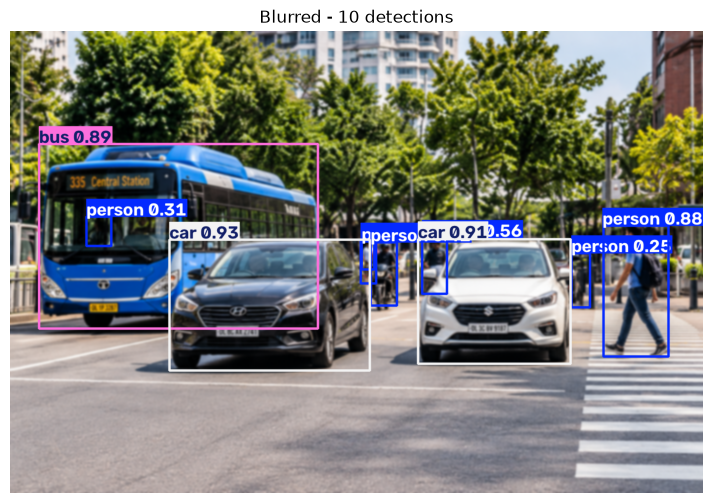

,Class ID,Class,Confidence,X1,Y1,X2,Y2,Area (px)
0,2,car,0.9316,353.8,462.7,797.7,752.4,128583
1,2,car,0.9052,904.6,461.3,1242.7,737.8,93481
2,5,bus,0.8922,64.1,250.2,682.3,659.1,252792
3,0,person,0.8788,1315.3,432.0,1459.3,721.5,41725
4,0,person,0.5556,913.2,458.4,968.5,582.5,6861
5,0,person,0.4078,799.9,468.1,858.0,608.1,8121
6,0,person,0.3520,779.0,466.6,807.1,528.9,1751
7,0,person,0.3142,169.5,411.0,224.2,476.2,3562
8,0,person,0.2549,777.8,464.1,811.0,559.1,3158
9,0,person,0.2536,1244.6,492.0,1285.7,612.8,4960


In [9]:
annotated, det_df, timing, runs = run_condition(model, images["Blurred"], DEVICE)
results["Blurred"] = {"annotated": annotated, "detections": det_df,
                      "timing": timing, "runs": runs}
cv2.imwrite(str(DETECTIONS_DIR / "03_blurred_detections.png"), annotated)

show_bgr(annotated, f"Blurred - {len(det_df)} detections")
det_df.reset_index(drop=True)

## 9. Detection on brightness + blur

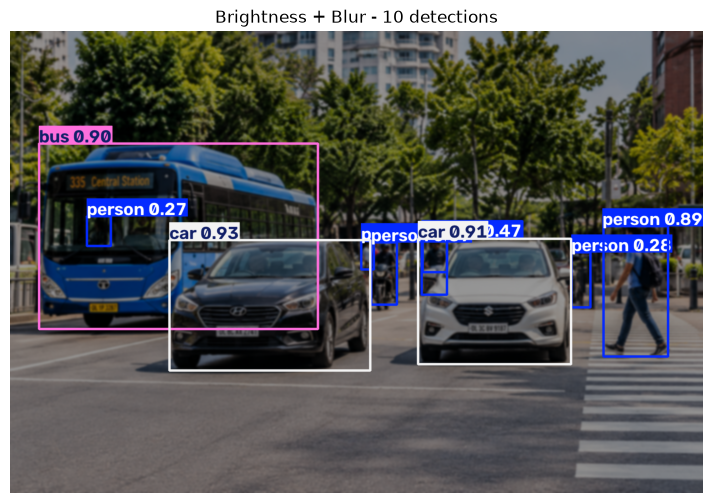

,Class ID,Class,Confidence,X1,Y1,X2,Y2,Area (px)
0,2,car,0.9328,353.8,463.8,798.2,752.1,128110
1,2,car,0.9073,904.2,460.8,1243.0,738.3,94001
2,5,bus,0.8969,64.7,249.2,682.5,660.3,253939
3,0,person,0.8854,1315.5,432.7,1459.0,721.4,41412
4,0,person,0.4743,912.4,458.3,968.1,584.6,7035
5,0,person,0.3937,800.1,468.1,857.7,607.0,7996
6,0,person,0.3384,778.8,465.8,806.6,528.3,1735
7,0,person,0.2939,914.7,459.6,968.7,534.6,4050
8,0,person,0.2823,1244.1,490.0,1287.0,612.8,5258
9,0,person,0.2748,170.1,410.4,223.3,476.7,3523


In [10]:
annotated, det_df, timing, runs = run_condition(model, images["Brightness + Blur"], DEVICE)
results["Brightness + Blur"] = {"annotated": annotated, "detections": det_df,
                                "timing": timing, "runs": runs}
cv2.imwrite(str(DETECTIONS_DIR / "04_brightness_plus_blur_detections.png"), annotated)

show_bgr(annotated, f"Brightness + Blur - {len(det_df)} detections")
det_df.reset_index(drop=True)

## 10. All four detection results together

A labeled 2 x 2 comparison figure, saved at a resolution suitable for the report.

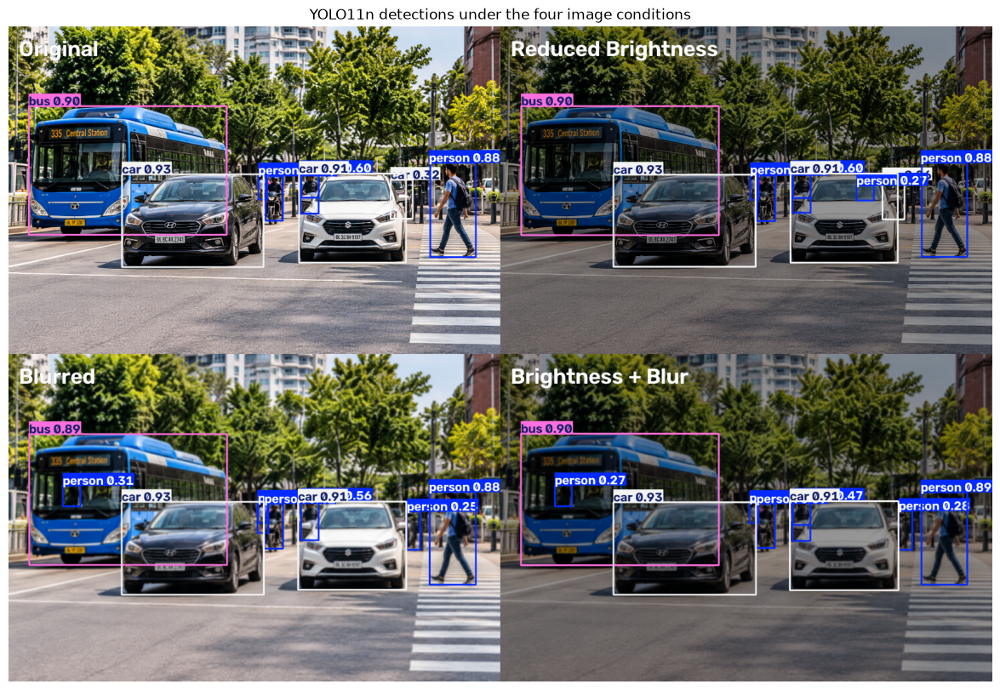

In [11]:
panel_w = 860
panels = []
for condition in CONDITION_FILES:
    image = results[condition]["annotated"]
    panel = cv2.resize(image, (panel_w, int(image.shape[0] * panel_w / image.shape[1])))
    # black outline + white fill keeps the label readable on any background
    cv2.putText(panel, condition, (18, 52), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 0, 0), 8, cv2.LINE_AA)
    cv2.putText(panel, condition, (18, 52), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (255, 255, 255), 3, cv2.LINE_AA)
    panels.append(panel)

comparison = np.vstack([np.hstack(panels[:2]), np.hstack(panels[2:])])
cv2.imwrite(str(OUTPUT_DIR / "comparison_figure.png"), comparison)
show_bgr(comparison, "YOLO11n detections under the four image conditions", figsize=(15, 10))

## 11. Performance comparison table

The metrics required by the assignment PDF, all measured from the actual detections:

- **Objects detected** - number of raw boxes the model outputs for that image.
- **Average confidence** - mean confidence over those raw boxes (computed on boxes, not on
  matched objects, for every condition alike).
- **Inference time** - mean wall-clock time of 3 timed runs (after a warm-up run) on the
  device printed in section 5; the supporting table shows the standard deviation.
- **Missed objects** - objects that **were detected in the original image** (the baseline)
  but have no matching box (same class, IoU >= 0.5) in that condition. The denominator is
  therefore the baseline, not every object in the scene - objects the model never detects in
  the original (e.g. the motorcycle, section 12) cannot be "missed" here by definition.

**Ambiguity flagged, not silently resolved.** The PDF lists a *MissedObjects* column for
every condition - including the Original row - but never defines the term, so the baseline
reading above cannot be the only one intended. Section 12.1 therefore also reports
*Reading B*: missed objects relative to a 12-object inventory of everything visibly present
in the scene. Both readings are printed side by side in `missed_objects_both_readings.csv`.

Duplicate boxes of one object are merged before counting, so a surviving twin box is never
mistaken for a lost object. The supporting table separates physical objects from raw boxes
and lists duplicate and newly appearing boxes.

In [12]:
original_df = results["Original"]["detections"]
performance_rows, support_rows, classification = [], [], {}

for condition in CONDITION_FILES:
    det_df = results[condition]["detections"]
    info = classify_condition_boxes(original_df, det_df)
    classification[condition] = info
    n_physical = len(info["physical_objects"])
    avg_conf = round(float(det_df["Confidence"].mean()), 4) if len(det_df) else 0.0
    missed_names = [info["physical_objects"][c]["class_name"] for c in info["missed"]]

    performance_rows.append({
        "Condition": condition,
        "Objects detected": len(det_df),
        "Average confidence": avg_conf,
        **results[condition]["timing"],
        "Missed objects": len(info["missed"]),
        "Missed object classes": "; ".join(missed_names) if missed_names else "-",
    })
    support_rows.append({
        "Condition": condition,
        f"Physical objects detected (of {n_physical})": n_physical - len(info["missed"]),
        "Duplicate boxes": len(info["duplicate_rows"]),
        "New or partial-counterpart boxes": len(info["new_rows"]) + len(info["ambiguous_rows"]),
        "Inference time std (ms)": round(float(np.std(results[condition]["runs"])), 1),
    })

performance_df = pd.DataFrame(performance_rows)
performance_df.to_csv(OUTPUT_DIR / "performance_comparison.csv", index=False)
support_df = pd.DataFrame(support_rows)
support_df.to_csv(OUTPUT_DIR / "supporting_performance.csv", index=False)
display(performance_df)
display(support_df)

,Condition,Objects detected,Average confidence,"Inference time (ms, mean of 3 runs)",Missed objects,Missed object classes
0,Original,9,0.6269,402.0,0,-
1,Reduced Brightness,10,0.5888,373.6,0,-
2,Blurred,10,0.5746,381.9,1,car
3,Brightness + Blur,10,0.5680,368.3,1,car


,Condition,Physical objects detected (of 8),Duplicate boxes,New or partial-counterpart boxes,Inference time std (ms)
0,Original,8,1,0,81.7
1,Reduced Brightness,8,1,1,16.7
2,Blurred,7,1,2,19.6
3,Brightness + Blur,7,1,2,6.4


In [13]:
# Full per-detection record used as supporting data for the report
full_rows = []
for condition in CONDITION_FILES:
    frame = results[condition]["detections"].copy()
    frame.insert(0, "Condition", condition)
    full_rows.append(frame)
all_detections_df = pd.concat(full_rows, ignore_index=True)
all_detections_df.to_csv(OUTPUT_DIR / "detections_all_conditions.csv", index=False)
print("Saved: outputs/performance_comparison.csv, outputs/detections_all_conditions.csv")

Saved: outputs/performance_comparison.csv, outputs/detections_all_conditions.csv


## 12. What is in the scene versus what the model detects (baseline inventory)

The 8 "physical objects" above are the objects the model detects **in the original image** at
the fixed 0.25 threshold. They are **not** the total number of objects in the scene, so this
cell makes the denominator explicit by comparing the baseline detections against what is
actually visible.

The scene clearly contains objects the detector does **not** pick up in the original
condition - most obviously the **motorcycle** in the middle of the road (with its rider),
which the model labels only as a `person` (the rider) and never as a `motorcycle`. To show
this is a threshold effect and not a wrong image, the cell below re-runs the model on the
*original* image at a **lower diagnostic threshold (conf >= 0.03)**. This diagnostic is used
only to identify which real objects sit just below the operating threshold; it plays no part
in the four-condition comparison, which always uses conf >= 0.25.

In [14]:
# Baseline inventory: objects visibly present in the original scene but not detected at the
# operating threshold. A lower conf (0.03) is used purely diagnostically to find sub-threshold
# counterparts of real objects; the four-condition experiment above stays at conf >= 0.25.
base = model.predict(images["Original"], conf=0.03, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
base_rows = []
for box in base.boxes:
    x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
    base_rows.append({"Class": base.names[int(box.cls[0])],
                      "Confidence": round(float(box.conf[0]), 4),
                      "X1": round(x1, 1), "Y1": round(y1, 1),
                      "X2": round(x2, 1), "Y2": round(y2, 1)})
base_df = pd.DataFrame(base_rows)

# Motorcycles the model can see at the diagnostic threshold (class motorcycle or bicycle).
two_wheel = base_df[base_df["Class"].isin(["motorcycle", "bicycle"])].sort_values(
    "Confidence", ascending=False)
print("Two-wheeler candidates in the ORIGINAL at diagnostic conf >= 0.03 "
      "(none reach the operating threshold 0.25):")
print(two_wheel.head(4).to_string(index=False) if len(two_wheel) else "  none")
operating = two_wheel[two_wheel["Confidence"] >= CONF_THRESHOLD]
print(f"-> highest two-wheeler score {two_wheel['Confidence'].max():.3f} vs operating threshold "
      f"{CONF_THRESHOLD}: {'detected' if len(operating) else 'NOT detected in any condition'}")

# The motorcycle is present in every modified image too - confirm it is never detected there.
for condition in CONDITION_FILES:
    df = results[condition]["detections"]
    n_moto = int((df["Class"].isin(["motorcycle", "bicycle"])).sum())
    print(f"  {condition:20s}: {n_moto} motorcycle/bicycle box(es) at conf >= {CONF_THRESHOLD}")

# Sub-threshold score of a real object known to sit in a region of the original image.
def best_in_region(rx1, ry1, rx2, ry2, cls):
    best = 0.0
    for box in base.boxes:
        if base.names[int(box.cls[0])] != cls:
            continue
        x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
        if rx1 <= (x1 + x2) / 2 <= rx2 and ry1 <= (y1 + y2) / 2 <= ry2:
            best = max(best, float(box.conf[0]))
    return round(best, 3)

inventory = [
    ("motorcycle (with rider, centre of road)", best_in_region(795, 500, 865, 625, "motorcycle")),
    ("same bike, mis-seen as 'bicycle'",        best_in_region(795, 500, 865, 625, "bicycle")),
    ("bus driver (behind windshield)",          best_in_region(150, 390, 265, 490, "person")),
    ("white-car occupant (behind glass)",       best_in_region(1100, 490, 1180, 550, "person")),
    ("figure behind bollards (right of car)",   best_in_region(1240, 490, 1300, 615, "person")),
    ("white vehicle cut off at right edge",     best_in_region(1470, 465, 1536, 525, "car")),
]
inv_df = pd.DataFrame(inventory, columns=["Object present in scene",
                                          "Best score in ORIGINAL (diagnostic conf 0.03)"])
inv_df["Detected in any condition (conf >= 0.25)?"] = np.where(
    inv_df["Best score in ORIGINAL (diagnostic conf 0.03)"] >= CONF_THRESHOLD, "yes", "no")
inv_df.to_csv(OUTPUT_DIR / "baseline_inventory.csv", index=False)
print("\nBaseline inventory - real objects the model does NOT detect at the operating threshold:")
print(inv_df.to_string(index=False))

baseline_detected = len(classification["Original"]["physical_objects"])
print(f"\nBaseline (original, conf >= {CONF_THRESHOLD}): {baseline_detected} unique physical objects "
      f"from {len(original_df)} raw boxes - this is the denominator for 'Missed objects', "
      f"not the total number of objects in the scene.")

Two-wheeler candidates in the ORIGINAL at diagnostic conf >= 0.03 (none reach the operating threshold 0.25):
     Class  Confidence    X1    Y1    X2    Y2
   bicycle      0.1276 802.8 529.1 853.0 618.7
motorcycle      0.0704 800.6 504.1 857.5 618.3
   bicycle      0.0586 800.6 503.4 858.2 617.7
   bicycle      0.0525 805.7 511.4 863.5 605.7
-> highest two-wheeler score 0.128 vs operating threshold 0.25: NOT detected in any condition
  Original            : 0 motorcycle/bicycle box(es) at conf >= 0.25
  Reduced Brightness  : 0 motorcycle/bicycle box(es) at conf >= 0.25
  Blurred             : 0 motorcycle/bicycle box(es) at conf >= 0.25
  Brightness + Blur   : 0 motorcycle/bicycle box(es) at conf >= 0.25

Baseline inventory - real objects the model does NOT detect at the operating threshold:
                Object present in scene  Best score in ORIGINAL (diagnostic conf 0.03) Detected in any condition (conf >= 0.25)?
motorcycle (with rider, centre of road)                             

### 12.1 Both readings of "Missed objects" (the brief leaves the term undefined)

The assignment PDF lists a **MissedObjects** column for *every* condition - including the
Original row - but never defines the term. Two defensible readings exist, so both are
reported rather than silently picking one:

- **Reading A - relative to the original detections (baseline).** Objects the model *can*
  detect in the original image that are then lost after the modification. This isolates the
  effect of the modification itself. Reported in the "Missed objects" column of the required
  comparison table (0 / 0 / 1 / 1).
- **Reading B - relative to everything visibly present in the scene.** Objects a human can
  identify in the photo that the model does not detect in that condition. This is closer to
  the usual object-detection meaning of a false negative and is non-zero even for the
  Original row (which is why the brief asks for the column there).

Reading B needs a **scene inventory**: a documented list of objects that are actually
visible. The list below was established by inspecting zoomed crops of the original image
(12 objects that can be identified with reasonable confidence). Each entry gives the region
used for matching; the figure drawn by this cell shows all 12 boxes so every entry can be
checked visually. Two judgement calls are stated openly:

- The **figure behind the bollards** (right of the distant car) is *excluded* from the
  inventory because its identity could not be confirmed; it is listed separately.
- The white vehicle at the right edge is **partly cut off / behind poles** but is clearly a
  vehicle, so it is counted and flagged as partially visible.

Matching uses the same rule as everywhere else: same class **and** IoU >= IOU_MATCH.

In [15]:
# Reading B: scene inventory = objects visibly present in the original image.
# Boxes were set from zoomed crops of the original; each is verified in the figure below.
SCENE_INVENTORY = [
    ("bus",       (63,   250, 682, 651), "blue city bus (left)"),
    ("car",       (354,  463, 797, 752), "black car (foreground left)"),
    ("car",       (907,  460, 1241, 739), "white car (foreground right)"),
    ("car",       (1194, 480, 1263, 602), "distant maroon car behind the white car (the failure case)"),
    ("car",       (1477, 474, 1525, 510), "white vehicle partly cut off at the right edge"),
    ("motorcycle",(800,  504, 858, 618), "motorcycle with rider (centre of road)"),
    ("person",    (1317, 427, 1459, 721), "pedestrian with backpack (right)"),
    ("person",    (912,  459, 969, 585), "standing person behind (boxed twice in the original)"),
    ("person",    (781,  466, 807, 542), "person in white shirt behind the rider"),
    ("person",    (803,  468, 857, 607), "motorcycle rider"),
    ("person",    (168,  411, 223, 477), "bus driver behind the windshield"),
    ("person",    (1115, 498, 1167, 544), "occupant behind the white-car windshield"),
]
UNCERTAIN = [("person", (1244, 497, 1289, 600), "figure behind bollards - identity NOT confirmed")]

CLASS_IDS = {name: cid for cid, name in
             results["Original"]["detections"].set_index("Class ID")["Class"].items()}

# Figure: every inventory object drawn on the annotated original, so the list is checkable.
vis = original.copy()
for k, (cls, (x1, y1, x2, y2), note) in enumerate(SCENE_INVENTORY, 1):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 200, 0), 3)
    cv2.putText(vis, f"{k}", (x1 + 4, y1 + 26), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 200, 0), 3,
                cv2.LINE_AA)
for cls, (x1, y1, x2, y2), _ in UNCERTAIN:
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 3)   # red = uncertain, not counted
legend = "green 1-12 = counted scene objects | red = uncertain (not counted)"
cv2.putText(vis, legend, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 8, cv2.LINE_AA)
cv2.putText(vis, legend, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
cv2.imwrite(str(OUTPUT_DIR / "scene_inventory_figure.png"), vis)

# Per condition: which inventory objects are detected (same class, IoU >= IOU_MATCH)?
scene_rows, scene_status = [], {}
for condition in CONDITION_FILES:
    cdf = results[condition]["detections"]
    detected, missed = [], []
    for k, (cls, box, note) in enumerate(SCENE_INVENTORY, 1):
        found = any(cdf.iloc[j]["Class"] == cls and iou(box, row_bbox(cdf.iloc[j])) >= IOU_MATCH
                    for j in range(len(cdf)))
        (detected if found else missed).append(k)
        scene_status.setdefault(condition, {})[k] = found
    scene_rows.append({
        "Condition": condition,
        "Scene objects detected (of 12)": len(detected),
        "Missed vs scene inventory (of 12)": len(missed),
        "Missed object numbers": ", ".join(str(k) for k in missed) if missed else "-",
        "Missed object names": "; ".join(SCENE_INVENTORY[k - 1][2] for k in missed) if missed else "-",
    })
scene_df = pd.DataFrame(scene_rows)
scene_df.to_csv(OUTPUT_DIR / "missed_objects_scene_inventory.csv", index=False)
print("Reading B - missed objects relative to the 12-object scene inventory:")
print(scene_df.to_string(index=False))

# Which objects change status vs the Original condition (gains/losses caused by the modification)?
print("\nChanges vs the Original condition (Reading B):")
for condition in CONDITION_FILES:
    if condition == "Original":
        continue
    gained = [k for k in range(1, 13)
              if scene_status[condition][k] and not scene_status["Original"][k]]
    lost = [k for k in range(1, 13)
            if not scene_status[condition][k] and scene_status["Original"][k]]
    g_txt = ", ".join(f"{k} ({SCENE_INVENTORY[k-1][2]})" for k in gained) or "none"
    l_txt = ", ".join(f"{k} ({SCENE_INVENTORY[k-1][2]})" for k in lost) or "none"
    print(f"  {condition:20s} gained: {g_txt} | lost: {l_txt}")

# The inventory entries that the model never detects in ANY condition:
never = [k for k in range(1, 13) if not any(scene_status[c][k] for c in CONDITION_FILES)]
print("\nNever detected in any condition (fixed detector blind spots, not modification effects):")
for k in never:
    print(f"  {k}. {SCENE_INVENTORY[k-1][2]} ({SCENE_INVENTORY[k-1][0]})")

inv_rows = []
for k, (cls, box, note) in enumerate(SCENE_INVENTORY, 1):
    inv_rows.append({"No.": k, "Class": cls, "Object (visible in original)": note,
                     "Region (x1, y1, x2, y2)": f"({box[0]}, {box[1]}, {box[2]}, {box[3]})",
                     **{f"Detected in {c}?": ("yes" if scene_status[c][k] else "no")
                        for c in CONDITION_FILES}})
for cls, box, note in UNCERTAIN:
    inv_rows.append({"No.": "-", "Class": cls, "Object (visible in original)": note + " [EXCLUDED]",
                     "Region (x1, y1, x2, y2)": f"({box[0]}, {box[1]}, {box[2]}, {box[3]})",
                     **{f"Detected in {c}?": "-" for c in CONDITION_FILES}})
pd.DataFrame(inv_rows).to_csv(OUTPUT_DIR / "scene_inventory.csv", index=False)

# Both readings side by side (Reading A comes from the required comparison table).
both_df = pd.DataFrame({
    "Condition": scene_df["Condition"],
    "Reading A: missed vs original detections (of 8)": performance_df["Missed objects"],
    "Reading B: missed vs scene inventory (of 12)": scene_df["Missed vs scene inventory (of 12)"],
})
both_df.to_csv(OUTPUT_DIR / "missed_objects_both_readings.csv", index=False)
print("\nBoth readings of 'Missed objects' (the brief does not define the term):")
print(both_df.to_string(index=False))

Reading B - missed objects relative to the 12-object scene inventory:
         Condition  Scene objects detected (of 12)  Missed vs scene inventory (of 12) Missed object numbers                                                                                                                                                                          Missed object names
          Original                               8                                  4          5, 6, 11, 12                           white vehicle partly cut off at the right edge; motorcycle with rider (centre of road); bus driver behind the windshield; occupant behind the white-car windshield
Reduced Brightness                               9                                  3              5, 6, 11                                                                     white vehicle partly cut off at the right edge; motorcycle with rider (centre of road); bus driver behind the windshield
           Blurred                     

### Why do the modified images show 10 detections while the original shows 9?

Every box that either doubles an already detected object or has no counterpart in the original
image is listed below with its best overlap against the original detections, so duplicates are
separated from genuinely new boxes. The figure shows each region in the original next to the
modified condition (annotated, so the boxes are visible) for visual verification.

In [16]:
extra_rows = []
for condition in ["Reduced Brightness", "Blurred", "Brightness + Blur"]:
    info = classification[condition]
    cond_df = results[condition]["detections"]
    groups = [
        ("duplicate of an already detected object", info["duplicate_rows"]),
        ("new - no counterpart in the original", info["new_rows"]),
        ("ambiguous - partial overlap only", info["ambiguous_rows"]),
    ]
    for category, rows in groups:
        for j in rows:
            det = cond_df.iloc[j]
            box = row_bbox(det)
            same = [iou(box, row_bbox(original_df.iloc[i])) for i in range(len(original_df))
                    if original_df.iloc[i]["Class ID"] == det["Class ID"]]
            best_same = max(same) if same else 0.0
            best_any = max(iou(box, row_bbox(original_df.iloc[i])) for i in range(len(original_df)))
            extra_rows.append({
                "Condition": condition,
                "Class": det["Class"],
                "Confidence": round(float(det["Confidence"]), 4),
                "Bounding box": f"({box[0]:.0f}, {box[1]:.0f}, {box[2]:.0f}, {box[3]:.0f})",
                "Best IoU vs same-class original box": round(best_same, 3),
                "Best IoU vs any original box": round(best_any, 3),
                "Category": category,
            })

extra_df = pd.DataFrame(extra_rows)
extra_df.to_csv(OUTPUT_DIR / "extra_detections.csv", index=False)
extra_df

,Condition,Class,Confidence,Bounding box,Best IoU vs same-class original box,Best IoU vs any original box,Category
0,Reduced Brightness,person,0.3029,"(914, 459, 970, 536)",0.970,0.970,duplicate of an already detected object
1,Reduced Brightness,person,0.2733,"(1113, 498, 1166, 544)",0.000,0.027,new - no counterpart in the original
2,Blurred,person,0.2549,"(778, 464, 811, 559)",0.645,0.645,duplicate of an already detected object
3,Blurred,person,0.3142,"(170, 411, 224, 476)",0.000,0.014,new - no counterpart in the original
4,Blurred,person,0.2536,"(1245, 492, 1286, 613)",0.000,0.175,new - no counterpart in the original
5,Brightness + Blur,person,0.2939,"(915, 460, 969, 535)",0.957,0.957,duplicate of an already detected object
6,Brightness + Blur,person,0.2823,"(1244, 490, 1287, 613)",0.000,0.180,new - no counterpart in the original
7,Brightness + Blur,person,0.2748,"(170, 410, 223, 477)",0.000,0.014,new - no counterpart in the original


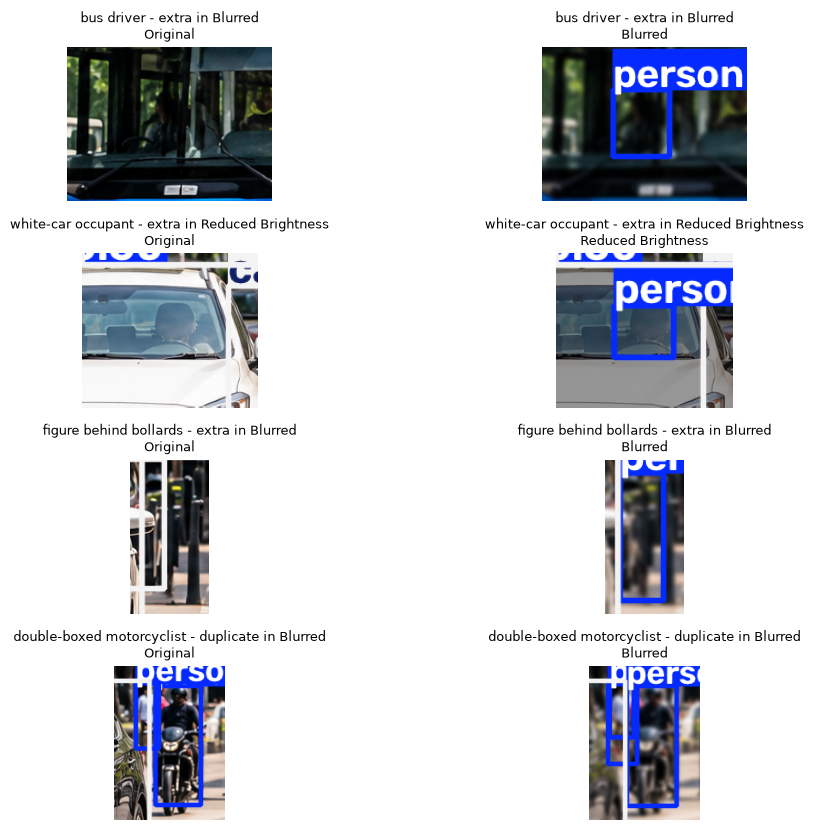

In [17]:
# Visual check: each extra region in the original and in a condition where the extra box appears.
region_specs = [
    ("bus driver - extra in Blurred", (100, 370, 300, 520), "Blurred"),
    ("white-car occupant - extra in Reduced Brightness", (1060, 450, 1220, 590), "Reduced Brightness"),
    ("figure behind bollards - extra in Blurred", (1230, 480, 1305, 625), "Blurred"),
    ("double-boxed motorcyclist - duplicate in Blurred", (755, 445, 885, 625), "Blurred"),
]
fig, axes = plt.subplots(len(region_specs), 2, figsize=(12, 2.1 * len(region_specs)))
for row, (label, (x1, y1, x2, y2), cond) in enumerate(region_specs):
    for col, cname in enumerate(["Original", cond]):
        crop = results[cname]["annotated"][y1:y2, x1:x2]
        axes[row, col].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{label}\n{cname}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "extra_detections_check.png", dpi=120, bbox_inches="tight")
plt.show()

## 13. Investigate two objects across all four conditions

Selection rule (stated explicitly so the choice is reproducible):

- **Object A** - the largest `bus` instance: a large, prominent object.
- **Object B** - the smallest vehicle instance in the original image: a small, distant object.

Matching uses class agreement plus bounding-box overlap (IoU). The two crops below let us verify
visually that the selected boxes really contain the intended objects.

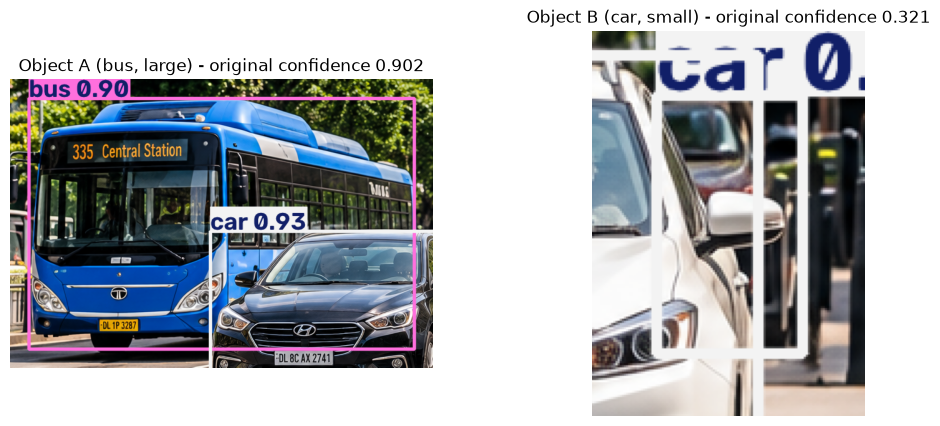

In [18]:
vehicles = original_df[original_df["Class"].isin(["car", "bus", "truck", "motorcycle"])]
object_a = vehicles[vehicles["Class"] == "bus"].sort_values("Area (px)", ascending=False).iloc[0]
object_b = vehicles[vehicles.index != object_a.name].sort_values("Area (px)").iloc[0]
tracked = {"Object A (bus, large)": object_a, "Object B (car, small)": object_b}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, row) in zip(axes, tracked.items()):
    x1, y1, x2, y2 = [int(v) for v in row_bbox(row)]
    crop = results["Original"]["annotated"][max(y1 - 30, 0):y2 + 30, max(x1 - 30, 0):x2 + 30]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{label} - original confidence {row['Confidence']:.3f}")
    ax.axis("off")
plt.show()

In [19]:
investigation_rows = []
for label, ref in tracked.items():
    ref_conf = ref["Confidence"]
    for condition in CONDITION_FILES:
        det_df = results[condition]["detections"]
        if condition == "Original":
            status, conf, box_iou, match_row = "Detected", ref_conf, 1.0, ref
        else:
            best_iou, match_row = 0.0, None
            for _, det in det_df[det_df["Class ID"] == ref["Class ID"]].iterrows():
                value = iou(row_bbox(ref), row_bbox(det))
                if value > best_iou:
                    best_iou, match_row = value, det
            if match_row is None or best_iou < 0.3:
                status, conf, box_iou, match_row = "Missed", None, 0.0, None
            elif best_iou < IOU_MATCH:
                status, conf, box_iou = "Uncertain", match_row["Confidence"], best_iou
            else:
                status, conf, box_iou = "Detected", match_row["Confidence"], best_iou

        # Undetected objects are marked missed/N/A; delta_C is reported as N/A (unforced).
        if conf is not None:
            conf_val = round(float(conf), 4)
            delta_c = round(float(ref_conf) - float(conf), 4)
        else:
            conf_val = "missed/N/A"
            delta_c = "N/A" 
        if match_row is not None:
            x1, y1, x2, y2 = row_bbox(match_row)
            rx1, ry1, rx2, ry2 = row_bbox(ref)
            shift = round(float(np.hypot((x1 + x2) / 2 - (rx1 + rx2) / 2,
                                         (y1 + y2) / 2 - (ry1 + ry2) / 2)), 1)
            w_change = round(100.0 * ((x2 - x1) - (rx2 - rx1)) / (rx2 - rx1), 1)
            h_change = round(100.0 * ((y2 - y1) - (ry2 - ry1)) / (ry2 - ry1), 1)
            bbox_text = f"({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})"
        else:
            shift = w_change = h_change = None
            bbox_text = "not detected"

        investigation_rows.append({
            "Object": label,
            "Condition": condition,
            "Detected": status,
            "Confidence": conf_val,
            "delta_C = C_original - C_modified": delta_c,
            "IoU vs original box": round(float(box_iou), 3),
            "Center shift (px)": shift,
            "Width change (%)": w_change,
            "Height change (%)": h_change,
            "Bounding box (x1, y1, x2, y2)": bbox_text,
        })

investigation_df = pd.DataFrame(investigation_rows)
investigation_df.to_csv(OUTPUT_DIR / "object_analysis.csv", index=False)
investigation_df

,Object,Condition,Detected,Confidence,delta_C = C_original - C_modified,IoU vs original box,Center shift (px),Width change (%),Height change (%),"Bounding box (x1, y1, x2, y2)"
0,"Object A (bus, large)",Original,Detected,0.9021,0.0000,1.000,0.0,0.0,0.0,"(63, 250, 682, 651)"
1,"Object A (bus, large)",Reduced Brightness,Detected,0.8993,0.0028,0.992,1.2,-0.2,0.4,"(65, 249, 682, 652)"
2,"Object A (bus, large)",Blurred,Detected,0.8922,0.0099,0.977,4.3,0.0,1.8,"(64, 250, 682, 659)"
3,"Object A (bus, large)",Brightness + Blur,Detected,0.8969,0.0052,0.974,4.5,-0.0,2.3,"(65, 249, 682, 660)"
4,"Object B (car, small)",Original,Detected,0.3205,0.0000,1.000,0.0,0.0,0.0,"(1194, 480, 1263, 602)"
5,"Object B (car, small)",Reduced Brightness,Detected,0.262,0.0585,0.969,1.3,1.2,1.0,"(1193, 480, 1263, 603)"
6,"Object B (car, small)",Blurred,Missed,missed/N/A,NaN,0.000,NaN,NaN,NaN,not detected
7,"Object B (car, small)",Brightness + Blur,Missed,missed/N/A,NaN,0.000,NaN,NaN,NaN,not detected


## 14. Failure-case analysis

Every *physical object* of the original image is compared with every modified condition.
If an object disappears (no matching box at IoU >= 0.5 in any modification), the most
confident disappeared object becomes the failure case; otherwise the largest confidence
drop is used. The first figure shows the same region in all four conditions (annotated,
original location in green); the second shows the raw pixels of that region.

In [20]:
candidates = []
for condition in ["Reduced Brightness", "Blurred", "Brightness + Blur"]:
    info = classification[condition]
    for c in info["missed"]:
        candidates.append((condition, info["physical_objects"][c]))

if candidates:
    condition, failed_obj = max(candidates, key=lambda item: max(item[1]["confidences"]))
    ref_row = max(failed_obj["rows"], key=lambda i: original_df.iloc[i]["Confidence"])
    failed = original_df.iloc[ref_row]
    kind = "physical object missed after modification"
else:
    drops = []
    for condition in ["Reduced Brightness", "Blurred", "Brightness + Blur"]:
        info = classification[condition]
        for c, boxes in enumerate(info["cluster_boxes"]):
            if not boxes:
                continue
            ref_conf = max(info["physical_objects"][c]["confidences"])
            cond_df = results[condition]["detections"]
            cond_conf = max(cond_df.iloc[j]["Confidence"] for j in boxes)
            drops.append((ref_conf - cond_conf, condition, c))
    drop, condition, failed_c = max(drops)
    failed_obj = classification[condition]["physical_objects"][failed_c]
    ref_row = max(failed_obj["rows"], key=lambda i: original_df.iloc[i]["Confidence"])
    failed = original_df.iloc[ref_row]
    kind = f"confidence dropped by {drop:.3f}"

cond_df = results[condition]["detections"]
same_class = cond_df[cond_df["Class ID"] == failed["Class ID"]]
nearest_same = (max(same_class.iloc, key=lambda r: iou(row_bbox(failed), row_bbox(r)))
                if len(same_class) else None)
nearest_any = (max(cond_df.iloc, key=lambda r: iou(row_bbox(failed), row_bbox(r)))
               if len(cond_df) else None)

print(f"Failure case: '{failed['Class']}' at confidence {failed['Confidence']:.4f} in Original, "
      f"{kind} in '{condition}'")
print(f"Original bounding box: {row_bbox(failed)}")
same_iou = (iou(row_bbox(failed), row_bbox(nearest_same)) if nearest_same is not None else 0.0)
if same_iou >= 0.1:
    print(f"Closest same-class box in '{condition}': conf {nearest_same['Confidence']:.4f}, "
          f"IoU {same_iou:.3f}")
else:
    print(f"No '{failed['Class']}' box overlaps the object in '{condition}' "
          f"(best same-class IoU {same_iou:.3f})")
if nearest_any is not None and nearest_any["Class"] != failed["Class"]:
    any_iou = iou(row_bbox(failed), row_bbox(nearest_any))
    print(f"Closest box of any class: '{nearest_any['Class']}' conf {nearest_any['Confidence']:.4f}, "
          f"IoU {any_iou:.3f}")
    if any_iou < 0.3:
        print("  -> overlap is partial only; this is a nearby box, not proof that the "
              "object itself was relabelled to that class.")

o_bright, o_sharp = quality_metrics(images["Original"])
c_bright, c_sharp = quality_metrics(images[condition])
print(f"Image quality in '{condition}': brightness {o_bright:.1f} -> {c_bright:.1f}, "
      f"Laplacian variance {o_sharp:.1f} -> {c_sharp:.1f}")

Failure case: 'car' at confidence 0.3205 in Original, physical object missed after modification in 'Blurred'
Original bounding box: [np.float64(1193.8), np.float64(479.7), np.float64(1262.8), np.float64(601.6)]
No 'car' box overlaps the object in 'Blurred' (best same-class IoU 0.062)
Closest box of any class: 'person' conf 0.2536, IoU 0.175
  -> overlap is partial only; this is a nearby box, not proof that the object itself was relabelled to that class.
Image quality in 'Blurred': brightness 116.7 -> 116.7, Laplacian variance 1415.7 -> 19.4


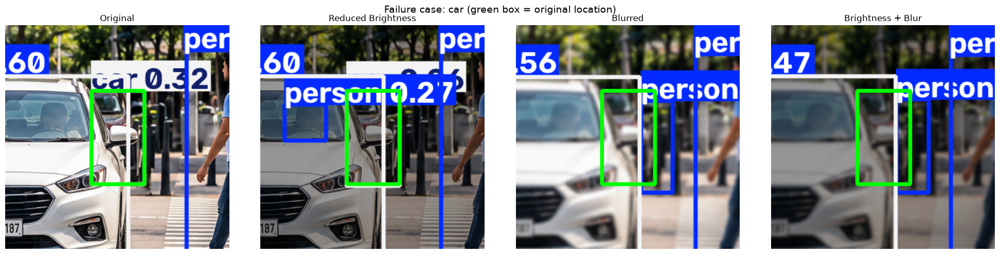

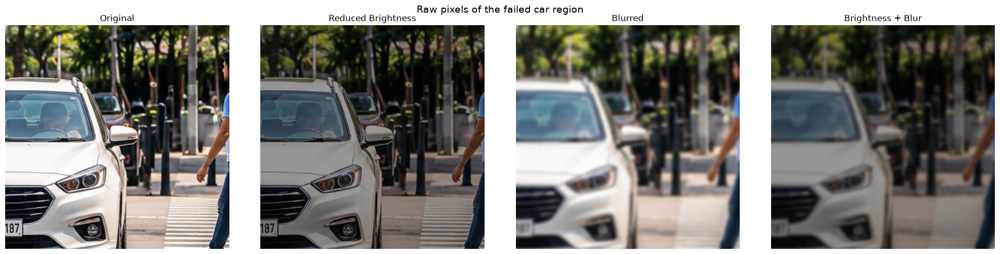

In [21]:
# Annotated crops: the same region in all four conditions (green = original location).
x1, y1, x2, y2 = [int(v) for v in row_bbox(failed)]
cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
side = int(2.4 * max(x2 - x1, y2 - y1))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, cond in zip(axes, CONDITION_FILES):
    image = results[cond]["annotated"]
    h, w = image.shape[:2]
    sx = min(max(cx - side // 2, 0), max(w - side, 0))
    sy = min(max(cy - side // 2, 0), max(h - side, 0))
    crop = image[sy:sy + side, sx:sx + side].copy()
    cv2.rectangle(crop, (x1 - sx, y1 - sy), (x2 - sx, y2 - sy), (0, 255, 0), 3)
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(cond)
    ax.axis("off")
plt.suptitle(f"Failure case: {failed['Class']} (green box = original location)", fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "failure_case_figure.png", dpi=150, bbox_inches="tight")
plt.show()

# Raw (unannotated) pixels of the same region - what the model actually sees.
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, cond in zip(axes, CONDITION_FILES):
    image = images[cond]
    h, w = image.shape[:2]
    sx = min(max(cx - side // 2, 0), max(w - side, 0))
    sy = min(max(cy - side // 2, 0), max(h - side, 0))
    crop = image[sy:sy + side, sx:sx + side]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(cond)
    ax.axis("off")
plt.suptitle(f"Raw pixels of the failed {failed['Class']} region", fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "failure_region_raw.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Observations and conclusion

The cell below prints the measured summary; the notes after it interpret the numbers.

In [22]:
time_col = [c for c in performance_df.columns if c.startswith("Inference time")][0]
print("Objects detected (boxes):", dict(zip(performance_df["Condition"], performance_df["Objects detected"])))
print("Physical objects detected:", dict(zip(support_df["Condition"],
      support_df[[c for c in support_df.columns if c.startswith("Physical")][0]])))
print("Average confidence:       ", dict(zip(performance_df["Condition"], performance_df["Average confidence"])))
print("Missed physical objects:  ", dict(zip(performance_df["Condition"], performance_df["Missed objects"])))
print("Inference time (ms):      ", dict(zip(performance_df["Condition"], performance_df[time_col])))
print("Per-run wall times (ms):  ", {c: results[c]["runs"] for c in CONDITION_FILES})
print("\ndelta_C per tracked object:")
for label in tracked:
    rows = investigation_df[investigation_df["Object"] == label]
    print(" ", label, dict(zip(rows["Condition"], rows["delta_C = C_original - C_modified"])))

failure_case = {
    "kind": kind,
    "condition": condition,
    "class_name": failed["Class"],
    "original_confidence": round(float(failed["Confidence"]), 4),
    "original_bbox": [round(float(v), 1) for v in row_bbox(failed)],
    "delta_C": round(float(failed["Confidence"]), 4),
    "nearest_same_class_iou": round(same_iou, 3),
    "nearest_any_class": (None if nearest_any is None else {
        "class_name": nearest_any["Class"],
        "iou": round(iou(row_bbox(failed), row_bbox(nearest_any)), 3),
        "confidence": round(float(nearest_any["Confidence"]), 4),
    }),
    "quality_original": {"mean_brightness": round(o_bright, 2), "laplacian_variance": round(o_sharp, 1)},
    "quality_condition": {"mean_brightness": round(c_bright, 2), "laplacian_variance": round(c_sharp, 1)},
}

condition_analysis = {}
for cond in CONDITION_FILES:
    info = classification[cond]
    condition_analysis[cond] = {
        "raw_boxes": len(results[cond]["detections"]),
        "physical_objects_total": len(info["physical_objects"]),
        "physical_objects_detected": len(info["physical_objects"]) - len(info["missed"]),
        "missed_physical_classes": [info["physical_objects"][c]["class_name"] for c in info["missed"]],
        "duplicate_boxes": len(info["duplicate_rows"]),
        "new_boxes": len(info["new_rows"]) + len(info["ambiguous_rows"]),
        "inference_runs_ms": results[cond]["runs"],
    }

summary = {
    "device": DEVICE,
    "timing_method": f"wall-clock around model.predict, {NUM_RUNS} timed runs after 1 warm-up run",
    "conditions": json.loads(performance_df.to_json(orient="records")),
    "condition_analysis": condition_analysis,
    "image_quality": {cond: {"mean_brightness": round(quality_metrics(images[cond])[0], 2),
                             "laplacian_variance": round(quality_metrics(images[cond])[1], 1)}
                      for cond in CONDITION_FILES},
    "tracked_objects": [{"label": label,
                         "class_name": row["Class"],
                         "original_confidence": round(float(row["Confidence"]), 4),
                         "original_bbox": [round(float(v), 1) for v in row_bbox(row)]}
                        for label, row in tracked.items()],
    "investigation": json.loads(investigation_df.to_json(orient="records")),
    "extra_detections": json.loads(extra_df.to_json(orient="records")),
    "failure_case": failure_case,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("\nSaved: outputs/summary.json")

Objects detected (boxes): {'Original': 9, 'Reduced Brightness': 10, 'Blurred': 10, 'Brightness + Blur': 10}
Physical objects detected: {'Original': 8, 'Reduced Brightness': 8, 'Blurred': 7, 'Brightness + Blur': 7}
Average confidence:        {'Original': 0.6269, 'Reduced Brightness': 0.5888, 'Blurred': 0.5746, 'Brightness + Blur': 0.568}
Missed physical objects:   {'Original': 0, 'Reduced Brightness': 0, 'Blurred': 1, 'Brightness + Blur': 1}
Inference time (ms):       {'Original': 402.0, 'Reduced Brightness': 373.6, 'Blurred': 381.9, 'Brightness + Blur': 368.3}
Per-run wall times (ms):   {'Original': [517.1, 335.3, 353.6], 'Reduced Brightness': [397.3, 361.0, 362.6], 'Blurred': [399.5, 354.6, 391.5], 'Brightness + Blur': [365.6, 377.1, 362.1]}

delta_C per tracked object:
  Object A (bus, large) {'Original': 0.0, 'Reduced Brightness': 0.0028, 'Blurred': 0.0099, 'Brightness + Blur': 0.0052}
  Object B (car, small) {'Original': 0.0, 'Reduced Brightness': 0.0585, 'Blurred': 0.3205, 'Bright


Saved: outputs/summary.json


**Evidence-based conclusions** (from the measured values printed above)

1. **Reduced brightness alone is well tolerated:** all 8 baseline-detected objects remain
   detected (0 missed under Reading A), average confidence falls only from 0.6269 to 0.5888,
   and the weakest car drops from 0.32 to 0.26 but stays above the fixed 0.25 threshold.
   Under Reading B (scene inventory) its missed count falls from 4 to 3, because the
   modification pushed the white-car occupant's score above the threshold.
2. **Blur is the damaging condition:** average confidence falls to 0.5746 (Blurred) and
   0.5680 (Brightness + Blur), and exactly **one baseline object is lost in each blur
   condition** - the small distant car (confidence 0.3205). In the box-level count the
   Blurred condition additionally loses one *duplicate box*: the original draws the
   standing person twice, and after blur only one of the two boxes survives. That person
   is still detected, so he/she is **not** counted as a missed object.
3. **Why both readings are reported, and why they disagree:** under Reading B the Blurred
   condition misses 4 of 12 scene objects - the *same* total as the Original condition -
   only because the lost car is offset by the bus driver's score crossing the threshold
   under blur. A single scene-inventory number would therefore **hide** the damage blur
   caused; Reading A (0 -> 1 baseline object lost) is the reading that isolates the
   modification's effect. This is precisely why the undefined brief term is reported twice.
4. **Object size decides robustness:** the large bus keeps delta_C <= 0.0099 and
   IoU >= 0.974 in every condition, while the small car loses its entire confidence
   (delta_C = 0.3205) under blur.
5. **Why the modified images show 10 boxes while the original shows 9:** the original's
   9 boxes cover 8 baseline objects (one person double-boxed); the modified images show
   7-8 baseline objects + 1 duplicate box + 1-2 new boxes. Every extra box has a real
   sub-threshold counterpart in the original (bus driver 0.171, white-car occupant 0.235,
   figure behind bollards 0.037 - the last one too weak to confirm visually). Blur and
   brightness shifted these borderline scores across the threshold in both directions - a
   new person box at another location does not compensate for the car that was lost.
6. **The baseline is not the whole scene:** the model detects 8 unique objects in the
   original, but the scene inventory holds 12 identifiable objects. The motorcycle is the
   clearest blind spot: it is never detected in **any** condition (peak score 0.128, and
   then as a 'bicycle'), so its absence is a fixed property of this detector on this
   scene, not an effect of the modifications.
7. **Inference timing:** mean wall-clock of 3 timed runs after a warm-up run on CPU, with
   per-run values printed above. The modified conditions' ranges overlap each other; the
   Original condition's first timed run is a clear cold-start outlier, and with only 3 runs
   per condition the mean differences cannot be separated from system noise. No speed
   effect of the image content and no performance improvement is claimed.

**Conclusion:** for this image and YOLO11n, reduced brightness has little effect, while
blur removes the small, low-contrast car because it destroys the object boundaries,
texture and contrast the detector relies on; the combined condition has the lowest
average confidence but does not remove additional baseline objects beyond blur alone.
These observations are limited to this one scene, this model and this modification
strength; they should not be generalised beyond them.

## 16. Experiment settings and references

The settings actually used during execution are exported to `outputs/experiment_settings.json`.

In [23]:
settings = {
    "model": MODEL_NAME,
    "weights": "COCO-pretrained (no training or fine-tuning in this assignment)",
    "device": DEVICE,
    "confidence_threshold": CONF_THRESHOLD,
    "image_size": IMGSZ,
    "runs_per_condition": NUM_RUNS,
    "timing_method": "wall-clock around model.predict, mean of 3 timed runs after 1 warm-up run",
    "iou_match_threshold": IOU_MATCH,
    "no_counterpart_iou": NO_COUNTERPART_IOU,
    "input_files": CONDITION_FILES,
    "modifications": {
        "supplied reduced brightness": "darker pixel values (measured mean brightness above)",
        "supplied blur": "Gaussian blur (measured Laplacian variance above)",
        "notebook demo regeneration": "convertScaleAbs alpha=0.6; GaussianBlur ksize 31x31 sigma 15",
    },
    "package_versions": {p: version(p) for p in
                         ["ultralytics", "opencv-python", "torch", "numpy", "pandas", "matplotlib", "pillow"]},
}
(OUTPUT_DIR / "experiment_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
settings

{'model': 'yolo11n.pt',
 'weights': 'COCO-pretrained (no training or fine-tuning in this assignment)',
 'device': 'cpu',
 'confidence_threshold': 0.25,
 'image_size': 640,
 'runs_per_condition': 3,
 'timing_method': 'wall-clock around model.predict, mean of 3 timed runs after 1 warm-up run',
 'iou_match_threshold': 0.5,
 'no_counterpart_iou': 0.3,
 'input_files': {'Original': '01_original_input.png',
  'Reduced Brightness': '02_reduced_brightness_input.png',
  'Blurred': '03_blurred_input.png',
  'Brightness + Blur': '04_brightness_plus_blur_input.png'},
 'modifications': {'supplied reduced brightness': 'darker pixel values (measured mean brightness above)',
  'supplied blur': 'Gaussian blur (measured Laplacian variance above)',
  'notebook demo regeneration': 'convertScaleAbs alpha=0.6; GaussianBlur ksize 31x31 sigma 15'},
 'package_versions': {'ultralytics': '8.4.184',
  'opencv-python': '5.0.0.93',
  'torch': '2.14.1',
  'numpy': '2.4.6',
  'pandas': '3.1.0',
  'matplotlib': '3.11.2

### References

1. Assignment brief: `CO4_Assignment.pdf`, Assignment-I (CO4) - required tasks, comparison
   table, and the confidence-change formula ΔC = C_original - C_modified.
2. J. Redmon, S. Divvala, R. Girshick, A. Farhadi. *You Only Look Once: Unified, Real-Time
   Object Detection.* CVPR 2016. (original YOLO paper)
3. Ultralytics. *Ultralytics YOLO documentation.* https://docs.ultralytics.com/ - API used in
   this notebook.
4. Ultralytics. *YOLO11 model card* (pretrained COCO weights):
   https://docs.ultralytics.com/models/yolo11/
5. COCO 80 class labels used by the pretrained weights:
   https://docs.ultralytics.com/datasets/detect/coco/
6. OpenCV documentation: `cv2.GaussianBlur` and `cv2.convertScaleAbs` (image modifications).

**Image source - needs to be supplied before submission.** The four input PNGs carry no
EXIF or text metadata (checked chunk-by-chunk), and no source is recorded anywhere in the
project, so the photo's origin **could not be verified**. No attribution has been invented.
If this photo was downloaded from the web, add its URL/licence here; if it is your own
photo, state "captured by the author".

**Submission files produced by this notebook** (all in `D:\AIPA_Assignments\ALM-4`):
the four input images, `outputs/detections/*.png` (annotated results for all four conditions),
`outputs/comparison_figure.png`, `outputs/failure_case_figure.png`,
`outputs/failure_region_raw.png`, `outputs/extra_detections_check.png`,
`outputs/performance_comparison.csv`, `outputs/supporting_performance.csv`,
`outputs/object_analysis.csv`, `outputs/extra_detections.csv`,
`outputs/baseline_inventory.csv`, `outputs/scene_inventory.csv`,
`outputs/missed_objects_scene_inventory.csv`, `outputs/missed_objects_both_readings.csv`,
`outputs/scene_inventory_figure.png`,
`outputs/detections_all_conditions.csv`, `outputs/summary.json`,
`outputs/experiment_settings.json`, plus the report in `report/`.